In [1]:
from __future__ import annotations

import json
from pathlib import Path

import cartopy
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnnotationBbox, HPacker, TextArea
import numpy as np
import pandas as pd
import rasterio
import torch
from rasterio.enums import Resampling
from rasterio.merge import merge
from scipy.ndimage import distance_transform_edt
from pyproj import Transformer

import movebench.paths as paths
from movebench.bench.evaluation import runner as evaluation_runner
from movebench.rasters import read_geotiff_window


/data/vision/beery/scratch/justin/micromamba/envs/movebench/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
RUNS_ROOT = paths.repo_root() / "results" / "bench" / "runs"
STUDY_ROWS = [
    ("Accio_967b7813_raw_merged", "White stork"),
    #("BartlamBrooks_c9b4f9b5_raw_merged", "Plains zebra"), 
    # ("stabach2020_wildebeest", "Wildebeest"), 
    # ("killian_elephants", "African bush elephant"),
    # ("cagnacci_eurodeer_Alta_Val_di_Non_Cervus_elaphus", "Deer"),
    # ("gstsdttir_d4074e60_raw_merged", 'Reindeer')
    # ("Hebblewhite_fb867768_raw_merged", "Wolf")
    ("Morato_8fed4a87_raw_merged", "Jaguar")
]
TIMESCALE_ORDER = ["1h", "12h", "1d", "7d"]
RANDOM_SEED =  8 # 54 #543 #123456

WORLD_MAP_PATH = (
    Path(cartopy.config["repo_data_dir"])
    / "raster"
    / "natural_earth"
    / "50-natural-earth-1-downsampled.png"
)
WORLD_MAP_IMAGE = plt.imread(WORLD_MAP_PATH)
WORLD_MAP_EXTENT = (-180.0, 180.0, -90.0, 90.0)
PLATE_CARREE = ccrs.PlateCarree()
WEB_MERCATOR = ccrs.epsg(3857)

TO_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
TO_LONLAT = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)
MAP_ROW_LANDSAT_ALPHA = 0.5
_trajectory_points_cache: dict[str, pd.DataFrame] = {}
_support_rows_cache: dict[tuple[str, str, str], pd.DataFrame] = {}
_dem_rgba_cache: dict[
    tuple[str, str, int, str], tuple[np.ndarray, tuple[float, float, float, float]]
] = {}
_landsat_rgb_cache: dict[
    tuple[str, str, int], tuple[np.ndarray, tuple[float, float, float, float]]
] = {}


In [3]:
METHOD_SPECS = [
    ("baseline_randomwalk", "CRW Baseline"),
    ("issf_linear", "iSSF"),
    ("issf_mlp", "iSSF MLP"),
    ("deepssf", "DeepSSF"),
    ("moveformer", "MoveFormer"),
]


def load_latest_runs(study_ids: list[str]) -> pd.DataFrame:
    rows: list[dict[str, object]] = []
    wanted_studies = set(study_ids)
    wanted_methods = {method for method, _ in METHOD_SPECS}
    for run_dir in sorted(RUNS_ROOT.iterdir()):
        if not run_dir.is_dir():
            continue
        resolved_path = run_dir / "resolved_run.json"
        pred_path = run_dir / "predictions" / "test_temporal.pt"
        summary_path = run_dir / "final_metrics" / "test_temporal" / "summary.json"
        if not resolved_path.exists() or not pred_path.exists() or not summary_path.exists():
            continue

        run_payload = json.loads(resolved_path.read_text())
        if run_payload.get("study_id") not in wanted_studies:
            continue
        method = str(run_payload.get("method"))
        if method not in wanted_methods:
            continue
        if run_payload.get("covariate_set") != "all":
            continue

        completed_at = max(
            resolved_path.stat().st_mtime,
            pred_path.stat().st_mtime,
            summary_path.stat().st_mtime,
        )
        rows.append(
            {
                "study_id": str(run_payload["study_id"]),
                "timescale": str(run_payload["timescale"]),
                "method": method,
                "run_dir": run_dir,
                "completed_at": float(completed_at),
            }
        )

    run_df = pd.DataFrame(rows)
    if run_df.empty:
        raise RuntimeError("No completed temporal prediction runs found.")
    return (
        run_df.sort_values("completed_at")
        .drop_duplicates(["study_id", "timescale", "method"], keep="last")
        .reset_index(drop=True)
    )


def trajectory_points(study_id: str) -> pd.DataFrame:
    if study_id not in _trajectory_points_cache:
        trajectory_path = paths.study_dir(study_id) / "trajectories.csv"
        points_df = pd.read_csv(
            trajectory_path,
            usecols=[
                "point_id",
                "location-long",
                "location-lat",
                "timestamp",
                "individual-local-identifier",
            ],
        ).rename(
            columns={
                "location-long": "lon",
                "location-lat": "lat",
                "individual-local-identifier": "individual_id",
            }
        )
        points_df["point_id"] = points_df["point_id"].astype(int)
        _trajectory_points_cache[study_id] = points_df.set_index("point_id", drop=False)
    return _trajectory_points_cache[study_id]


def support_rows_for_run(run_row) -> pd.DataFrame:
    cache_key = (str(run_row.study_id), str(run_row.timescale), str(run_row.method))
    if cache_key not in _support_rows_cache:
        run_dir = Path(run_row.run_dir)
        run_payload = json.loads((run_dir / "resolved_run.json").read_text())
        selected_splits = evaluation_runner._selected_splits_for_split(
            run_payload=run_payload,
            split_key="test_temporal",
        )
        support_rows, _ = evaluation_runner._support_rows_for_split(
            study_id=str(run_row.study_id),
            split_key="test_temporal",
            timescale_key=str(run_row.timescale),
            selected_splits=selected_splits,
        )
        _support_rows_cache[cache_key] = pd.DataFrame(
            {
                "point_id_start": [int(row["point_id_start"]) for row in support_rows],
                "point_id_end": [int(row["point_id_end"]) for row in support_rows],
                "in_support": [bool(row["in_support"]) for row in support_rows],
            }
        )
    return _support_rows_cache[cache_key]


def choose_shared_start_point(run_rows: list[object], rng: np.random.Generator) -> int:
    point_sets = []
    in_support_sets = []
    for run_row in run_rows:
        support_df = support_rows_for_run(run_row)
        point_sets.append(set(support_df["point_id_start"].tolist()))
        in_support_sets.append(
            set(support_df.loc[support_df["in_support"], "point_id_start"].tolist())
        )

    if not point_sets:
        raise RuntimeError("choose_shared_start_point requires at least one run row")

    common_in_support = set.intersection(*in_support_sets) if in_support_sets else set()
    common_all = set.intersection(*point_sets)
    candidate_ids = sorted(common_in_support or common_all)
    if not candidate_ids:
        raise RuntimeError("No shared temporal test start point exists across requested runs")
    return int(candidate_ids[int(rng.integers(len(candidate_ids)))])


def grid_edges_3857(
    start_lon: float,
    start_lat: float,
    pixel_size_m: float,
    shape: tuple[int, int],
) -> tuple[np.ndarray, np.ndarray, float, float]:
    height, width = shape
    x_offsets_m = (
        np.arange(width + 1, dtype=np.float64) - (width // 2) - 0.5
    ) * float(pixel_size_m)
    y_offsets_m = (
        (height // 2) - np.arange(height + 1, dtype=np.float64) + 0.5
    ) * float(pixel_size_m)
    start_x_m, start_y_m = TO_3857.transform(float(start_lon), float(start_lat))
    x_edges_m = float(start_x_m) + x_offsets_m
    y_edges_m = float(start_y_m) + y_offsets_m
    x_mesh_m, y_mesh_m = np.meshgrid(x_edges_m, y_edges_m)
    return x_mesh_m, y_mesh_m, float(start_x_m), float(start_y_m)


def chip_width_label(width_m: float) -> str:
    chip_width_km = float(np.round(float(width_m) / 1000.0))
    return f"{chip_width_km:g} km"


def first_available_panel(study_panels: list[list[dict[str, object] | None]]) -> dict[str, object]:
    for timescale_panels in study_panels:
        for panel in timescale_panels:
            if panel is not None:
                return panel
    raise RuntimeError("Study is missing panels for the qualitative figure")


def first_available_timescale_panel(
    timescale_panels: list[dict[str, object] | None],
) -> dict[str, object] | None:
    for panel in timescale_panels:
        if panel is not None:
            return panel
    return None


def landsat_rgba_for_panel(
    panel: dict[str, object],
) -> tuple[np.ndarray, tuple[float, float, float, float]]:
    cache_key = (
        str(panel["study_id"]),
        str(panel["rasters_hash"]),
        int(panel["point_id_start"]),
    )
    if cache_key not in _landsat_rgb_cache:
        raster_root = (
            paths.study_dir(str(panel["study_id"]))
            / "rasters"
            / str(panel["rasters_hash"])
        )
        meta = json.loads((raster_root / "chips_meta.json").read_text())
        band_ids = meta["chip_groups"]["high_res"]["band_ids_in_order"]
        rgb_indexes = [
            band_ids.index(f"landsat.{band}") + 1 for band in ["red", "green", "blue"]
        ]
        chip_path = (
            raster_root
            / "chips"
            / "high_res"
            / f"{int(panel['point_id_start']):05d}.tif"
        )
        with rasterio.open(chip_path) as ds:
            rgb_chw = ds.read(rgb_indexes).astype(np.float32)
            left_x_m, bottom_y_m = TO_3857.transform(
                float(ds.bounds.left),
                float(ds.bounds.bottom),
            )
            right_x_m, top_y_m = TO_3857.transform(
                float(ds.bounds.right),
                float(ds.bounds.top),
            )
            extent = (
                float(left_x_m),
                float(right_x_m),
                float(bottom_y_m),
                float(top_y_m),
            )
        valid = np.isfinite(rgb_chw) & (rgb_chw > -1000.0)
        valid_px = valid.all(axis=0)
        rgba = np.zeros((*valid_px.shape, 4), dtype=np.float32)
        rgba[..., 3] = valid_px.astype(np.float32)
        rgb_hwc = np.moveaxis(rgb_chw, 0, -1)
        if np.any(valid_px):
            rgb_valid = rgb_hwc[valid_px]
            lo, hi = np.quantile(rgb_valid, [0.02, 0.98])
            scale = max(float(hi - lo), 1e-6)
            rgba[..., :3][valid_px] = np.clip(
                (rgb_valid - float(lo)) / scale,
                0.0,
                1.0,
            )
            rgba[..., :3] = np.power(rgba[..., :3], 0.85)
        _landsat_rgb_cache[cache_key] = (rgba, extent)
    return _landsat_rgb_cache[cache_key]


def panel_bounds_latlon(
    panel: dict[str, object],
) -> tuple[float, float, float, float]:
    lon0, lat0 = TO_LONLAT.transform(panel["xlim_m"][0], panel["ylim_m"][0])
    lon1, lat1 = TO_LONLAT.transform(panel["xlim_m"][1], panel["ylim_m"][1])
    return (
        float(min(lon0, lon1)),
        float(min(lat0, lat1)),
        float(max(lon0, lon1)),
        float(max(lat0, lat1)),
    )


def dem_rgba_for_panel(
    panel: dict[str, object],
) -> tuple[np.ndarray, tuple[float, float, float, float]]:
    cache_key = (
        str(panel["study_id"]),
        str(panel["rasters_hash"]),
        int(panel["point_id_start"]),
        str(panel["timescale"]),
    )
    if cache_key not in _dem_rgba_cache:
        bounds_latlon = panel_bounds_latlon(panel)
        tile_dir = (
            paths.study_dir(str(panel["study_id"]))
            / "rasters"
            / str(panel["rasters_hash"])
            / "tiles"
            / "dem"
        )
        tile_index = json.loads((tile_dir / "index.json").read_text())
        matches = []
        min_lon, min_lat, max_lon, max_lat = bounds_latlon
        for tile in tile_index.get("tiles", []):
            tile_bounds = tile.get("bounds", {})
            if (
                float(tile_bounds["min_lon"]) <= max_lon
                and float(tile_bounds["max_lon"]) >= min_lon
                and float(tile_bounds["min_lat"]) <= max_lat
                and float(tile_bounds["max_lat"]) >= min_lat
            ):
                matches.append(tile_dir / tile["file"])
        if not matches:
            raise FileNotFoundError(f"No DEM tiles overlap {bounds_latlon!r}")
        if len(matches) == 1:
            dem_raster = read_geotiff_window(
                matches[0],
                bounds_latlon,
                max_window_hw=(400, 400),
                resampling=Resampling.bilinear,
            )
            dem_array = dem_raster.array[0].astype(np.float32, copy=False)
        else:
            datasets = [rasterio.open(path) for path in matches]
            try:
                mosaic, _transform = merge(datasets, bounds=bounds_latlon)
                dem_array = mosaic[0].astype(np.float32, copy=False)
            finally:
                for ds in datasets:
                    ds.close()
        valid = np.isfinite(dem_array) & (dem_array > -9000.0)
        filled = dem_array.copy()
        fill_value = float(np.nanmedian(filled[valid])) if np.any(valid) else 0.0
        filled[~valid] = fill_value
        center_lat = 0.5 * (min_lat + max_lat)
        dy_m = max(111320.0 * (max_lat - min_lat) / max(filled.shape[0], 1), 1.0)
        dx_m = max(
            111320.0
            * np.cos(np.deg2rad(center_lat))
            * (max_lon - min_lon)
            / max(filled.shape[1], 1),
            1.0,
        )
        grad_y, grad_x = np.gradient(filled, dy_m, dx_m)
        slope = np.pi / 2.0 - np.arctan(np.hypot(grad_x, grad_y))
        aspect = np.arctan2(-grad_x, grad_y)
        azimuth = np.deg2rad(315.0)
        altitude = np.deg2rad(45.0)
        shade = (
            np.sin(altitude) * np.sin(slope)
            + np.cos(altitude) * np.cos(slope) * np.cos(azimuth - aspect)
        )
        shade = np.clip((shade + 1.0) / 2.0, 0.0, 1.0)
        elev_lo, elev_hi = np.quantile(filled[valid], [0.02, 0.98]) if np.any(valid) else (0.0, 1.0)
        elev_norm = np.clip((filled - float(elev_lo)) / max(float(elev_hi - elev_lo), 1e-6), 0.0, 1.0)
        dem_gray = np.clip(0.10 + 0.65 * shade + 0.25 * elev_norm, 0.0, 1.0)
        rgba = np.zeros((*filled.shape, 4), dtype=np.float32)
        rgba[..., :3][valid] = dem_gray[valid, None]
        ocean_mask = ~valid
        if np.any(ocean_mask):
            ocean_dist = distance_transform_edt(ocean_mask).astype(np.float32)
            ocean_scale = max(float(np.quantile(ocean_dist[ocean_mask], 0.95)), 1.0)
            ocean_norm = np.clip(ocean_dist / ocean_scale, 0.0, 1.0)
            ocean_rgb = np.stack(
                [
                    0.68 - 0.16 * ocean_norm,
                    0.76 - 0.13 * ocean_norm,
                    0.82 - 0.08 * ocean_norm,
                ],
                axis=-1,
            )
            rgba[..., :3][ocean_mask] = ocean_rgb[ocean_mask]
        rgba[..., 3] = 1.0
        left_x_m, bottom_y_m = TO_3857.transform(min_lon, min_lat)
        right_x_m, top_y_m = TO_3857.transform(max_lon, max_lat)
        extent = (
            float(left_x_m),
            float(right_x_m),
            float(bottom_y_m),
            float(top_y_m),
        )
        _dem_rgba_cache[cache_key] = (rgba, extent)
    return _dem_rgba_cache[cache_key]


def make_study_title_line_boxes(panel: dict[str, object]) -> tuple[HPacker, HPacker]:
    base_props = {"fontsize": 14}
    symbol_props = {"fontsize": 19}
    start_line = HPacker(
        children=[
            TextArea("Start point", textprops=base_props),
            TextArea("\u2022", textprops={"fontsize": 26}),
            TextArea(
                f"({panel['start_lat']:.2f}, {panel['start_lon']:.2f}, {panel['start_timestamp']})",
                textprops=base_props,
            ),
        ],
        align="center",
        pad=0,
        sep=0,
    )
    end_line = HPacker(
        children=[
            TextArea("End point ", textprops=base_props),
            TextArea("\u2605", textprops={"fontsize": 17}),
            TextArea(" at different time horizons", textprops=base_props),
        ],
        align="center",
        pad=0,
        sep=0,
    )
    return start_line, end_line


_grid_spec_cache: dict[tuple[str, str], tuple[tuple[int, int], float]] = {}


def reference_grid_spec(study_id: str, timescale: str) -> tuple[tuple[int, int], float]:
    cache_key = (str(study_id), str(timescale))
    if cache_key not in _grid_spec_cache:
        for method, _method_label in METHOD_SPECS:
            run_row = run_lookup.get((cache_key[0], cache_key[1], method))
            if run_row is None:
                continue
            pred_payload = torch.load(
                Path(run_row.run_dir) / "predictions" / "test_temporal.pt",
                map_location="cpu",
            )
            if "scores" not in pred_payload:
                continue
            _grid_spec_cache[cache_key] = (
                tuple(int(v) for v in pred_payload["scores"].shape[1:]),
                float(pred_payload["pixel_size_m"]),
            )
            break
        else:
            raise RuntimeError(
                f"No grid prediction artifact found for {cache_key[0]} {cache_key[1]}"
            )
    return _grid_spec_cache[cache_key]


def legacy_discrete_logp_hw(
    pred_payload: dict[str, object],
    pred_index: int,
    shape: tuple[int, int],
    pixel_size_m: float,
) -> np.ndarray:
    height, width = shape
    coords_m = torch.as_tensor(pred_payload["coords_m"][pred_index], dtype=torch.float64).numpy()
    probs = torch.as_tensor(pred_payload["probs"][pred_index], dtype=torch.float64).numpy()
    total_mass = float(np.sum(probs))
    if not np.isfinite(total_mass) or total_mass <= 0.0:
        raise ValueError("Legacy discrete prediction artifact has non-positive probability mass")
    probs = probs / total_mass
    col_float = coords_m[:, 0] / float(pixel_size_m) + (width // 2)
    row_float = (height // 2) - coords_m[:, 1] / float(pixel_size_m)
    row0 = np.floor(row_float).astype(np.int64)
    col0 = np.floor(col_float).astype(np.int64)
    row_w = row_float - row0
    col_w = col_float - col0
    probs_hw = np.zeros((height, width), dtype=np.float64)
    for drow, dcol, weight in [
        (0, 0, (1.0 - row_w) * (1.0 - col_w)),
        (0, 1, (1.0 - row_w) * col_w),
        (1, 0, row_w * (1.0 - col_w)),
        (1, 1, row_w * col_w),
    ]:
        rows = row0 + drow
        cols = col0 + dcol
        valid = (rows >= 0) & (rows < height) & (cols >= 0) & (cols < width)
        if np.any(valid):
            np.add.at(probs_hw, (rows[valid], cols[valid]), probs[valid] * weight[valid])
    in_window_mass = float(np.sum(probs_hw))
    if not np.isfinite(in_window_mass) or in_window_mass <= 0.0:
        raise ValueError("Legacy discrete prediction artifact has no support on the reference grid")
    probs_hw /= in_window_mass
    logp_hw = np.full((height, width), -np.inf, dtype=np.float64)
    positive = probs_hw > 0.0
    logp_hw[positive] = np.log(probs_hw[positive])
    return logp_hw


def build_panel(run_row, point_id_start: int) -> dict[str, object]:
    support_df = support_rows_for_run(run_row)
    picked = support_df.loc[support_df["point_id_start"] == int(point_id_start)]
    if len(picked) != 1:
        raise ValueError(
            f"{run_row.study_id} {run_row.timescale} missing shared start point {point_id_start}"
        )
    picked_row = picked.iloc[0]

    run_dir = Path(run_row.run_dir)
    run_payload = json.loads((run_dir / "resolved_run.json").read_text())
    pred_payload = torch.load(
        run_dir / "predictions" / "test_temporal.pt",
        map_location="cpu",
    )
    pred_point_ids = pred_payload["point_id_start"].numpy().astype(np.int64)
    pred_match = np.flatnonzero(pred_point_ids == int(point_id_start))
    if pred_match.size != 1:
        raise ValueError(
            f"{run_dir.name} expected one prediction row for point_id_start={point_id_start}"
        )
    pred_index = int(pred_match[0])

    points_df = trajectory_points(str(run_row.study_id))
    start_row = points_df.loc[int(point_id_start)]
    end_row = points_df.loc[int(picked_row.point_id_end)]
    if "scores" in pred_payload:
        pixel_size_m = float(pred_payload["pixel_size_m"])
        logp_hw = torch.log_softmax(
            pred_payload["scores"][pred_index].reshape(-1),
            dim=0,
        ).reshape(pred_payload["scores"].shape[1:]).numpy()
    else:
        shape, pixel_size_m = reference_grid_spec(str(run_row.study_id), str(run_row.timescale))
        logp_hw = legacy_discrete_logp_hw(pred_payload, pred_index, shape, pixel_size_m)

    x_edges_m, y_edges_m, start_x_m, start_y_m = grid_edges_3857(
        float(start_row.lon),
        float(start_row.lat),
        float(pixel_size_m),
        logp_hw.shape,
    )
    xlim_m = (float(np.nanmin(x_edges_m)), float(np.nanmax(x_edges_m)))
    ylim_m = (float(np.nanmin(y_edges_m)), float(np.nanmax(y_edges_m)))
    end_x_m, end_y_m = TO_3857.transform(float(end_row.lon), float(end_row.lat))
    return {
        "study_id": str(run_row.study_id),
        "timescale": str(run_row.timescale),
        "rasters_hash": str(run_payload["rasters_hash"]),
        "point_id_start": int(point_id_start),
        "point_id_end": int(picked_row.point_id_end),
        "in_support": bool(picked_row.in_support),
        "start_lon": float(start_row.lon),
        "start_lat": float(start_row.lat),
        "start_timestamp": str(start_row.timestamp),
        "individual_id": str(start_row.individual_id),
        "start_x_m": float(start_x_m),
        "start_y_m": float(start_y_m),
        "end_x_m": float(end_x_m),
        "end_y_m": float(end_y_m),
        "x_edges_m": x_edges_m,
        "y_edges_m": y_edges_m,
        "xlim_m": xlim_m,
        "ylim_m": ylim_m,
        "chip_width_m": xlim_m[1] - xlim_m[0],
        "logp_hw": logp_hw,
    }


latest_runs = load_latest_runs([study_id for study_id, _ in STUDY_ROWS])
run_lookup = {
    (str(row.study_id), str(row.timescale), str(row.method)): row
    for row in latest_runs.itertuples(index=False)
}
rng = np.random.default_rng(RANDOM_SEED)
panels: list[list[list[dict[str, object] | None]]] = []
for study_id, _species in STUDY_ROWS:
    study_run_rows = [
        run_lookup[(study_id, timescale, method)]
        for timescale in TIMESCALE_ORDER
        for method, _method_label in METHOD_SPECS
        if (study_id, timescale, method) in run_lookup
    ]
    shared_point_id = choose_shared_start_point(study_run_rows, rng)
    row_panels: list[list[dict[str, object] | None]] = []
    for timescale in TIMESCALE_ORDER:
        timescale_panels: list[dict[str, object] | None] = []
        for method, _method_label in METHOD_SPECS:
            run_row = run_lookup.get((study_id, timescale, method))
            timescale_panels.append(
                None if run_row is None else build_panel(run_row, shared_point_id)
            )
        row_panels.append(timescale_panels)
    panels.append(row_panels)

map_panels = [
    [first_available_timescale_panel(timescale_panels) for timescale_panels in study_panels]
    for study_panels in panels
]

study_title_panels = [
    first_available_panel(study_panels)
    for study_panels in panels
]

surfaces = [
    panel["logp_hw"]
    for study_panels in panels
    for timescale_panels in study_panels
    for panel in timescale_panels
    if panel is not None
]
stack = np.concatenate([surface[np.isfinite(surface)] for surface in surfaces])
vmin_logp, vmax_logp = np.quantile(stack, [0.01, 0.99]).tolist()


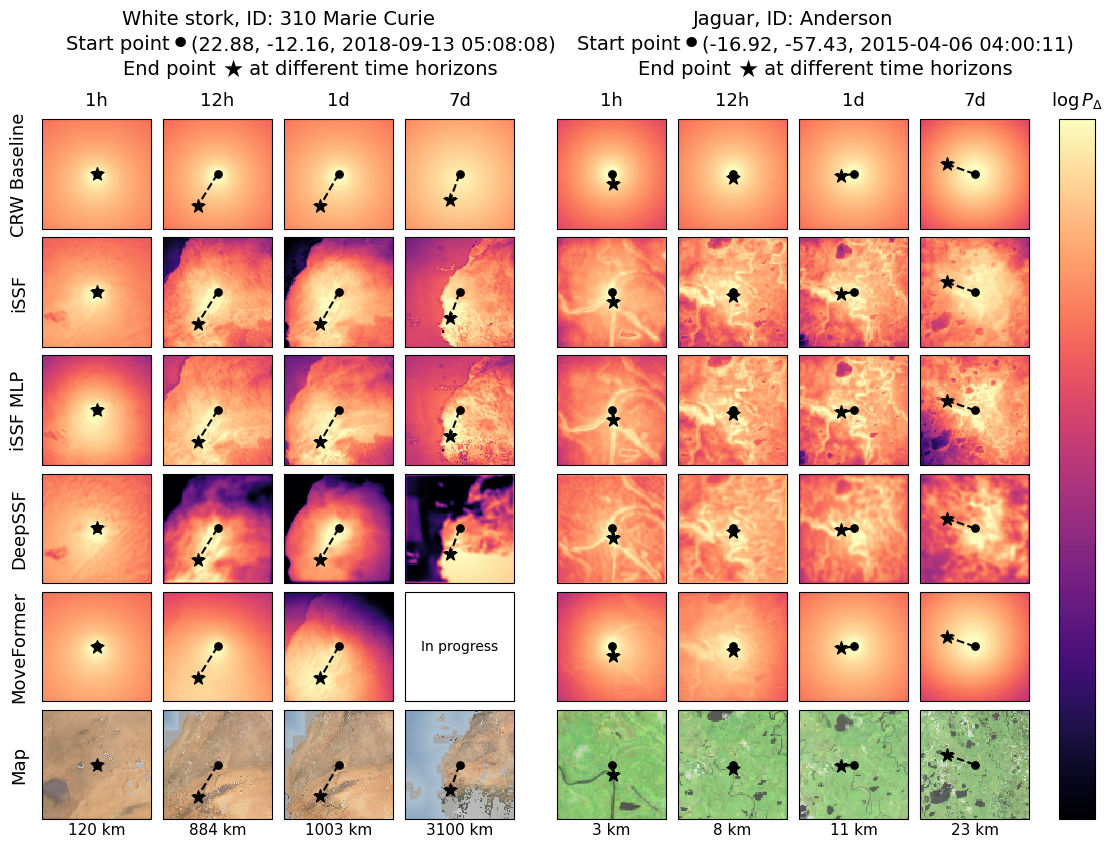

In [5]:
row_labels = [method_label for _method, method_label in METHOD_SPECS] + ["Map"]
method_rows = len(METHOD_SPECS)
fig = plt.figure(figsize=(11.5, 10))
plot_cols_per_study = len(TIMESCALE_ORDER)
plot_col_positions = [0, 1, 2, 3, 5, 6, 7, 8]
grid = fig.add_gridspec(
    len(row_labels),
    len(plot_col_positions) + 2,
    left=0.06,
    right=0.96,
    top=0.76,
    bottom=0.06,
    wspace=0.01,
    hspace=0.08,
    width_ratios=[1, 1, 1, 1, 0.25, 1, 1, 1, 1, 0.3],
)
axes = np.empty((len(row_labels), len(plot_col_positions)), dtype=object)
color_mesh = None
for row_idx, row_label in enumerate(row_labels):
    is_map_row = row_idx == method_rows
    for study_idx, (_study_id, _species_name) in enumerate(STUDY_ROWS):
        for timescale_idx, _timescale in enumerate(TIMESCALE_ORDER):
            plot_col = study_idx * plot_cols_per_study + timescale_idx
            ax = fig.add_subplot(
                grid[row_idx, plot_col_positions[plot_col]],
                projection=WEB_MERCATOR,
            )
            axes[row_idx, plot_col] = ax
            panel = (
                map_panels[study_idx][timescale_idx]
                if is_map_row
                else panels[study_idx][timescale_idx][row_idx]
            )
            if study_idx == 0 and timescale_idx == 0:
                ax.set_ylabel(row_label, fontsize=13, labelpad=10)

            if panel is None:
                ax.text(
                    0.5,
                    0.5,
                    "In progress",
                    ha="center",
                    va="center",
                    transform=ax.transAxes,
                )
                ax.set_xticks([])
                ax.tick_params(axis="x", bottom=False, labelbottom=False, top=False)
                ax.set_yticks([])
                continue

            if is_map_row:
                dem_rgba, dem_extent = dem_rgba_for_panel(panel)
                ax.imshow(
                    dem_rgba,
                    extent=dem_extent,
                    transform=WEB_MERCATOR,
                    interpolation="bicubic",
                    origin="upper",
                    zorder=0,
                )
                if MAP_ROW_LANDSAT_ALPHA > 0:
                    landsat_rgba, landsat_extent = landsat_rgba_for_panel(panel)
                    overlay_rgba = landsat_rgba.copy()
                    overlay_rgba[..., 3] *= float(MAP_ROW_LANDSAT_ALPHA)
                    ax.imshow(
                        overlay_rgba,
                        extent=landsat_extent,
                        transform=WEB_MERCATOR,
                        interpolation="nearest",
                        origin="upper",
                        zorder=1,
                    )
                ax.set_facecolor("#d7e1e6")
            else:
                # ax.imshow(
                #     WORLD_MAP_IMAGE,
                #     extent=WORLD_MAP_EXTENT,
                #     transform=PLATE_CARREE,
                #     interpolation="bilinear",
                #     origin="upper",
                #     alpha=0.96,
                #     zorder=0,
                # )
                ax.set_facecolor("#eef2f3")
                color_mesh = ax.pcolormesh(
                    panel["x_edges_m"],
                    panel["y_edges_m"],
                    panel["logp_hw"],
                    shading="auto",
                    cmap="magma",
                    vmin=vmin_logp,
                    vmax=vmax_logp,
                    # alpha=0.5,
                    rasterized=True,
                    zorder=1,
                    transform=WEB_MERCATOR,
                )
            ax.plot(
                [panel["start_x_m"], panel["end_x_m"]],
                [panel["start_y_m"], panel["end_y_m"]],
                color="black",
                linewidth=1.5,
                linestyle="--",
                zorder=2,
                transform=WEB_MERCATOR,
            )
            ax.scatter(
                panel["start_x_m"],
                panel["start_y_m"],
                color="black",
                s=28,
                zorder=3,
                transform=WEB_MERCATOR,
            )
            ax.scatter(
                panel["end_x_m"],
                panel["end_y_m"],
                color="black",
                marker="*",
                s=95,
                zorder=4,
                transform=WEB_MERCATOR,
            )
            ax.set_xlim(*panel["xlim_m"])
            ax.set_ylim(*panel["ylim_m"])
            ax.set_aspect("equal")
            if row_idx == len(row_labels) - 1:
                x_center_m = 0.5 * (panel["xlim_m"][0] + panel["xlim_m"][1])
                ax.set_xticks([x_center_m], crs=WEB_MERCATOR)
                ax.set_xticklabels([chip_width_label(panel["chip_width_m"])], fontsize=11)
                ax.tick_params(
                    axis="x",
                    bottom=True,
                    labelbottom=True,
                    top=False,
                    length=0,
                    pad=2,
                )
            else:
                ax.set_xticks([])
                ax.tick_params(axis="x", bottom=False, labelbottom=False, top=False)
            ax.set_yticks([])

top_row_y = axes[0, 0].get_position().y1
study_species_y = 0.87
study_start_y = 0.82
study_end_y = 0.79
for plot_col in range(axes.shape[1]):
    top_ax = axes[0, plot_col]
    x_center = 0.5 * (top_ax.get_position().x0 + top_ax.get_position().x1)
    fig.text(
        x_center,
        top_row_y + 0.01,
        TIMESCALE_ORDER[plot_col % plot_cols_per_study],
        ha="center",
        va="bottom",
        fontsize=13,
    )

for study_idx, ((_study_id, species_name), panel) in enumerate(zip(STUDY_ROWS, study_title_panels)):
    left_col = study_idx * plot_cols_per_study
    right_col = left_col + plot_cols_per_study - 1
    left_ax = axes[0, left_col]
    right_ax = axes[0, right_col]
    x_center = 0.5 * (left_ax.get_position().x0 + right_ax.get_position().x1)
    fig.text(
        x_center,
        study_species_y,
        f"{species_name}, ID: {panel['individual_id']}",
        ha="center",
        va="top",
        fontsize=14,
    )
    start_line, end_line = make_study_title_line_boxes(panel)
    fig.add_artist(
        AnnotationBbox(
            start_line,
            (x_center, study_start_y),
            xybox=(x_center, study_start_y),
            xycoords="figure fraction",
            boxcoords="figure fraction",
            box_alignment=(0.5, 1.0),
            frameon=False,
            pad=0,
            annotation_clip=False,
        )
    )
    fig.add_artist(
        AnnotationBbox(
            end_line,
            (x_center, study_end_y),
            xybox=(x_center, study_end_y),
            xycoords="figure fraction",
            boxcoords="figure fraction",
            box_alignment=(0.5, 1.0),
            frameon=False,
            pad=0,
            annotation_clip=False,
        )
    )

if color_mesh is not None:
    cax = fig.add_subplot(grid[:, 9])
    cax_pos = cax.get_position()
    cax.remove()
    cax = fig.add_axes([cax_pos.x0 + 0.02, cax_pos.y0, cax_pos.width, cax_pos.height])
    cbar = fig.colorbar(color_mesh, cax=cax)
    cbar.ax.set_title(r'$\log P_{\Delta}$', pad=10, fontsize=13)
    cbar.set_ticks([])
    cbar.ax.tick_params(length=0)

plt.savefig('qualitative_draft_v4.pdf',bbox_inches='tight',dpi=200)